In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

# Make project root importable when this notebook is opened from notebooks/
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import ACTIVITIES, load_dataset

plt.style.use("default")
sns.set_theme(context="notebook", style="whitegrid")
print("Project root:", PROJECT_ROOT)


Project root: c:\Users\nandi\OneDrive\Desktop\tinyml-har-esp32


In [3]:
X_train, y_train, X_test, y_test = load_dataset()

print(f"X_train: {X_train.shape}, dtype={X_train.dtype}")
print(f"y_train: {y_train.shape}, dtype={y_train.dtype}")
print(f"X_test:  {X_test.shape}, dtype={X_test.dtype}")
print(f"y_test:  {y_test.shape}, dtype={y_test.dtype}")

assert X_train.shape == (7352, 128, 3)
assert X_test.shape == (2947, 128, 3)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()
assert set(np.unique(y_train)) == set(range(6))
assert set(np.unique(y_test)) == set(range(6))

print("\nAll shape, label, and finite-value checks passed.")


X_train: (7352, 128, 3), dtype=float32
y_train: (7352,), dtype=int64
X_test:  (2947, 128, 3), dtype=float32
y_test:  (2947,), dtype=int64

All shape, label, and finite-value checks passed.


In [4]:
summary = pd.DataFrame({
    "split": ["train", "test"],
    "windows": [len(y_train), len(y_test)],
    "time_steps_per_window": [X_train.shape[1], X_test.shape[1]],
    "axes": [X_train.shape[2], X_test.shape[2]],
    "window_duration_seconds": [X_train.shape[1] / 50, X_test.shape[1] / 50],
})
summary


,split,windows,time_steps_per_window,axes,window_duration_seconds
0,train,7352,128,3,2.56
1,test,2947,128,3,2.56


In [5]:
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

class_distribution = pd.DataFrame({
    "activity": ACTIVITIES,
    "train_count": [int(train_counts.get(i, 0)) for i in range(6)],
    "test_count": [int(test_counts.get(i, 0)) for i in range(6)],
})
class_distribution


,activity,train_count,test_count
0,WALKING,1226,496
1,WALKING_UPSTAIRS,1073,471
2,WALKING_DOWNSTAIRS,986,420
3,SITTING,1286,491
4,STANDING,1374,532
5,LAYING,1407,537


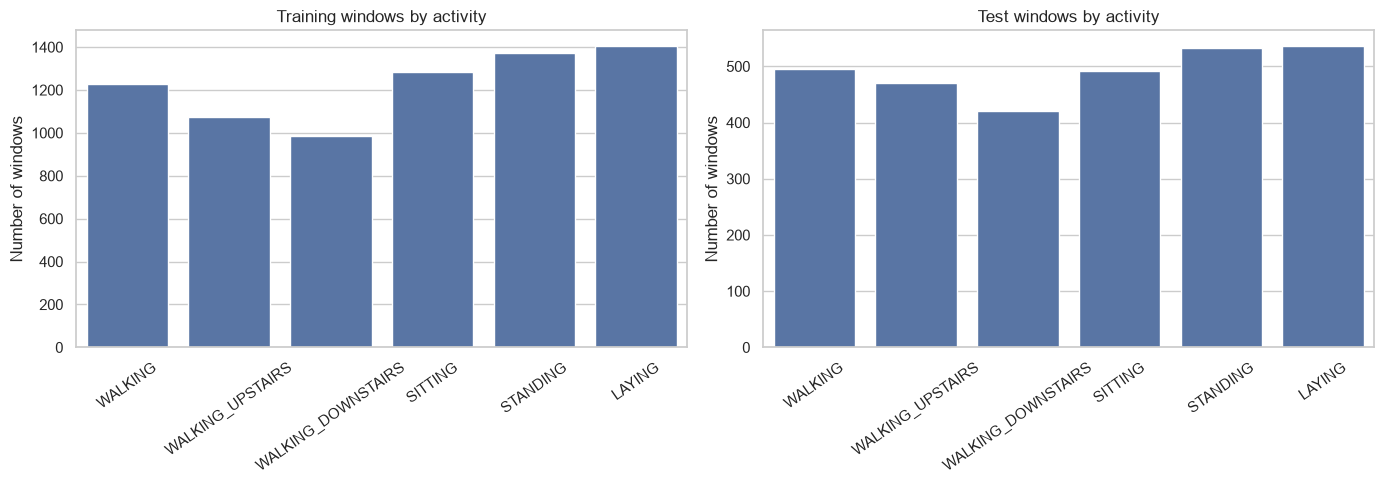

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=class_distribution, x="activity", y="train_count", ax=axes[0])
axes[0].set_title("Training windows by activity")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of windows")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(data=class_distribution, x="activity", y="test_count", ax=axes[1])
axes[1].set_title("Test windows by activity")
axes[1].set_xlabel("")
axes[1].set_ylabel("Number of windows")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()


In [7]:
axis_names = ["X", "Y", "Z"]

integrity = pd.DataFrame({
    "axis": axis_names,
    "train_min": X_train.min(axis=(0, 1)),
    "train_max": X_train.max(axis=(0, 1)),
    "train_mean": X_train.mean(axis=(0, 1)),
    "train_std": X_train.std(axis=(0, 1)),
    "test_min": X_test.min(axis=(0, 1)),
    "test_max": X_test.max(axis=(0, 1)),
    "test_mean": X_test.mean(axis=(0, 1)),
    "test_std": X_test.std(axis=(0, 1)),
})
integrity


,axis,train_min,train_max,train_mean,train_std,test_min,test_max,test_mean,test_std
0,X,-0.466556,2.197618,0.803952,0.414090,-0.277735,2.112682,0.817406,0.406498
1,Y,-1.582079,1.217350,0.028755,0.390842,-1.588211,1.134313,0.004349,0.412027
2,Z,-1.639609,1.281363,0.086497,0.357683,-1.347501,1.043383,0.080672,0.307911


In [8]:
print("NaN values in train:", np.isnan(X_train).sum())
print("Infinite values in train:", np.isinf(X_train).sum())
print("NaN values in test:", np.isnan(X_test).sum())
print("Infinite values in test:", np.isinf(X_test).sum())
print("Train labels:", np.unique(y_train))
print("Test labels:", np.unique(y_test))


NaN values in train: 0
Infinite values in train: 0
NaN values in test: 0
Infinite values in test: 0
Train labels: [0 1 2 3 4 5]
Test labels: [0 1 2 3 4 5]


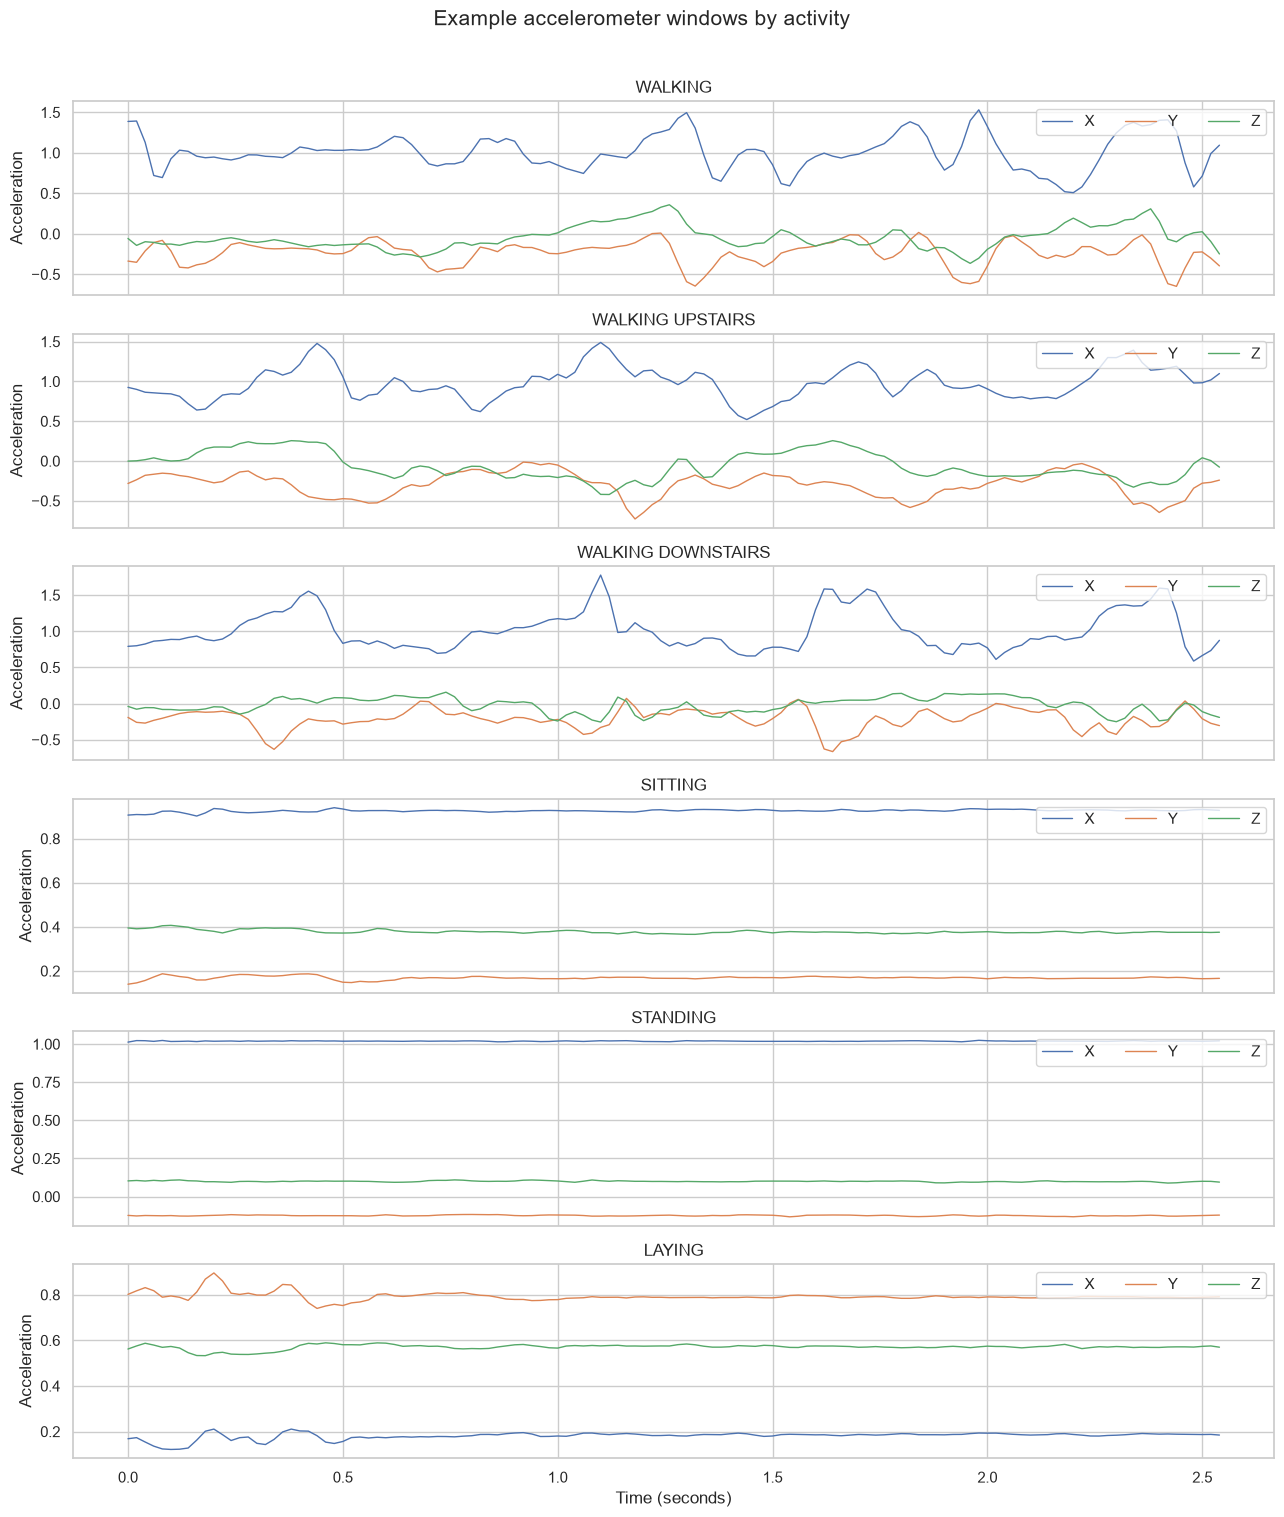

In [9]:
# Select the first training window for each activity.
time = np.arange(128) / 50.0
fig, axes = plt.subplots(6, 1, figsize=(13, 15), sharex=True)

for class_id, ax in enumerate(axes):
    idx = np.flatnonzero(y_train == class_id)[0]
    window = X_train[idx]
    for axis_id, axis_name in enumerate(axis_names):
        ax.plot(time, window[:, axis_id], label=axis_name, linewidth=1)
    ax.set_title(ACTIVITIES[class_id].replace("_", " "))
    ax.set_ylabel("Acceleration")
    ax.legend(ncol=3, loc="upper right")

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Example accelerometer windows by activity", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()


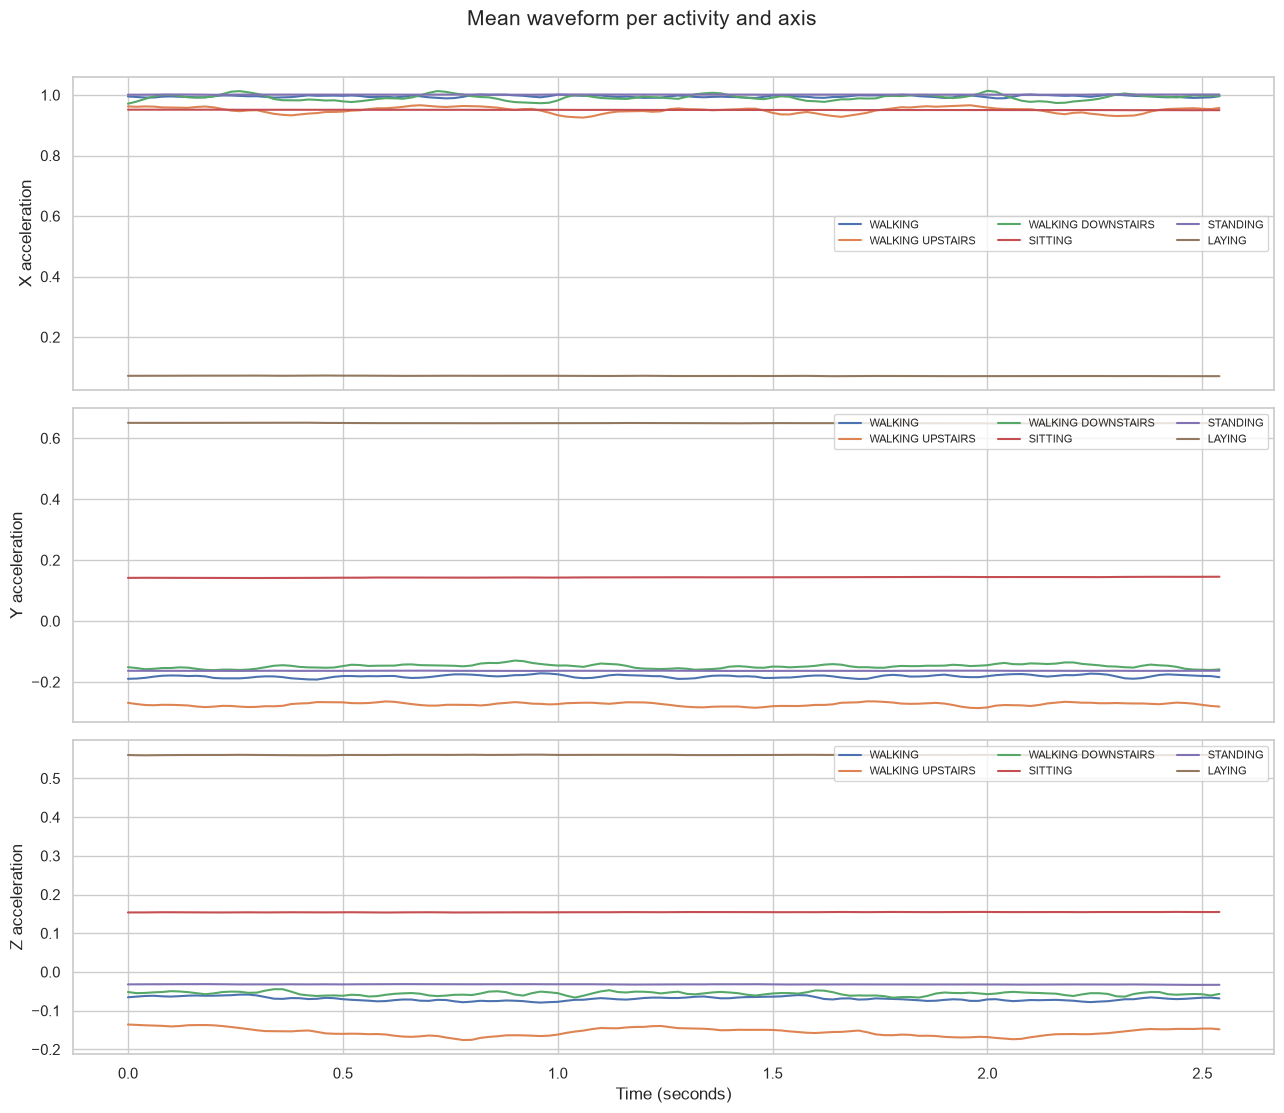

In [10]:
# Class-average waveforms are useful summaries, but may hide variation between people/windows.
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

for axis_id, ax in enumerate(axes):
    for class_id, activity in enumerate(ACTIVITIES):
        class_windows = X_train[y_train == class_id]
        mean_waveform = class_windows[:, :, axis_id].mean(axis=0)
        ax.plot(time, mean_waveform, label=activity.replace("_", " "))
    ax.set_ylabel(f"{axis_names[axis_id]} acceleration")
    ax.legend(ncol=3, fontsize=8)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Mean waveform per activity and axis", y=1.01, fontsize=15)
plt.tight_layout()
plt.show()


In [11]:
def summarize_windows(X):
    # Features are descriptive only; they are not used to train a model in this notebook.
    rows = []
    for i, window in enumerate(X):
        row = {}
        for axis_id, axis_name in enumerate(axis_names):
            values = window[:, axis_id]
            row[f"{axis_name}_mean"] = values.mean()
            row[f"{axis_name}_std"] = values.std()
            row[f"{axis_name}_min"] = values.min()
            row[f"{axis_name}_max"] = values.max()
            row[f"{axis_name}_range"] = values.max() - values.min()
        row["magnitude_mean"] = np.linalg.norm(window, axis=1).mean()
        row["magnitude_std"] = np.linalg.norm(window, axis=1).std()
        row["activity_id"] = int(y_train[i])
        rows.append(row)
    return pd.DataFrame(rows)

features_train = summarize_windows(X_train)
features_train["activity"] = features_train["activity_id"].map(
    {i: name.replace("_", " ") for i, name in enumerate(ACTIVITIES)}
)
features_train.head()


,X_mean,X_std,X_min,X_max,X_range,Y_mean,Y_std,Y_min,Y_max,Y_range,Z_mean,Z_std,Z_min,Z_max,Z_range,magnitude_mean,magnitude_std,activity_id,activity
0,1.019305,0.001791,1.012817,1.024606,0.011789,-0.124262,0.003270,-0.132631,-0.117210,0.015421,0.099732,0.003970,0.088742,0.109485,0.020743,1.031695,0.001948,4,STANDING
1,1.019448,0.001932,1.012893,1.024606,0.011713,-0.122936,0.004930,-0.132631,-0.108560,0.024071,0.096939,0.004918,0.081100,0.105788,0.024688,1.031423,0.002041,4,STANDING
2,1.019927,0.002904,1.009013,1.027664,0.018651,-0.124997,0.006460,-0.137142,-0.108560,0.028582,0.092897,0.006145,0.081100,0.105788,0.024688,1.031787,0.002926,4,STANDING
3,1.020349,0.002574,1.009013,1.027664,0.018651,-0.130493,0.004029,-0.143545,-0.116749,0.026796,0.087654,0.004945,0.076888,0.098737,0.021849,1.032407,0.002554,4,STANDING
4,1.020255,0.001949,1.013645,1.026194,0.012549,-0.130209,0.003876,-0.143545,-0.121456,0.022090,0.084999,0.003637,0.074595,0.093388,0.018793,1.032050,0.002027,4,STANDING


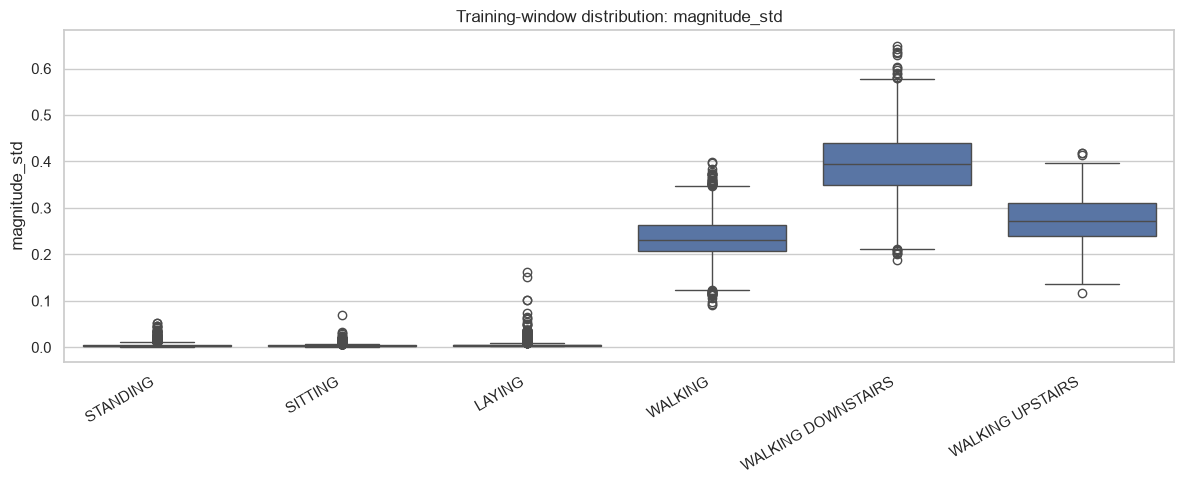

In [12]:
feature_to_plot = "magnitude_std"
plt.figure(figsize=(12, 5))
sns.boxplot(data=features_train, x="activity", y=feature_to_plot)
plt.title(f"Training-window distribution: {feature_to_plot}")
plt.xlabel("")
plt.ylabel(feature_to_plot)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


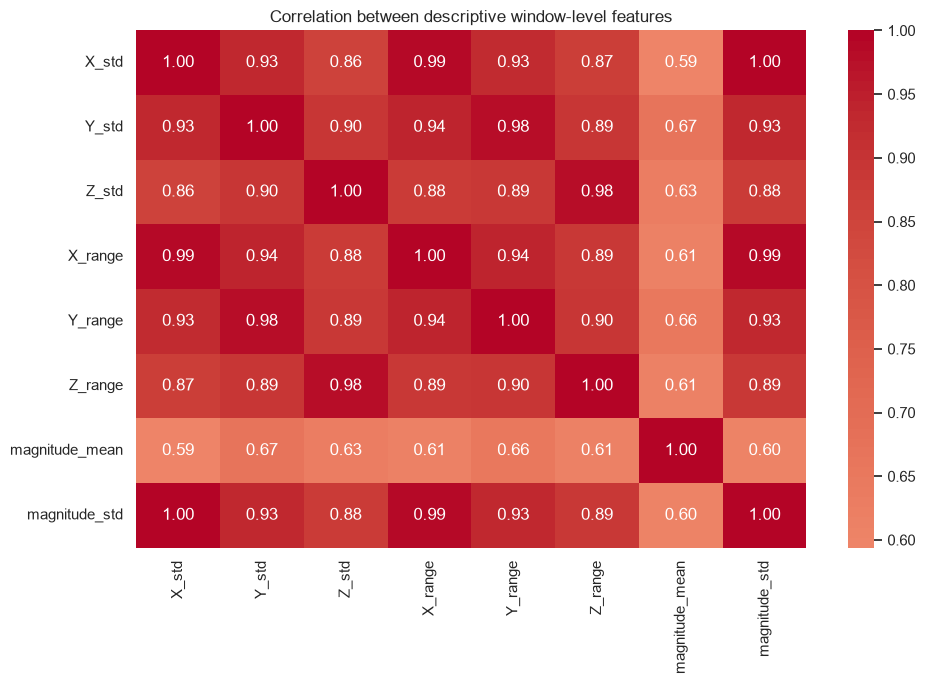

In [13]:
corr_cols = [
    "X_std", "Y_std", "Z_std",
    "X_range", "Y_range", "Z_range",
    "magnitude_mean", "magnitude_std",
]
plt.figure(figsize=(10, 7))
sns.heatmap(features_train[corr_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlation between descriptive window-level features")
plt.tight_layout()
plt.show()


In [14]:
FIG_DIR = PROJECT_ROOT / "results" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Example: save the current active figure after rerunning a plot cell.
# plt.savefig(FIG_DIR / "figure_name.png", dpi=160, bbox_inches="tight")
print("EDA figure directory:", FIG_DIR)


EDA figure directory: c:\Users\nandi\OneDrive\Desktop\tinyml-har-esp32\results\eda


In [15]:

def missing_value_report(X, y, split_name):
    sensor_nan = int(np.isnan(X).sum())
    sensor_inf = int(np.isinf(X).sum())
    label_missing = int(pd.isna(y).sum())

    report = pd.DataFrame({
        "check": [
            "Missing sensor values (NaN)",
            "Infinite sensor values",
            "Missing labels",
            "Windows containing NaN",
            "Windows containing infinity",
        ],
        "count": [
            sensor_nan,
            sensor_inf,
            label_missing,
            int(np.isnan(X).any(axis=(1, 2)).sum()),
            int(np.isinf(X).any(axis=(1, 2)).sum()),
        ],
    })

    print(f"{split_name.upper()} MISSING-VALUE REPORT")
    display(report)

missing_value_report(X_train, y_train, "train")
missing_value_report(X_test, y_test, "test")


TRAIN MISSING-VALUE REPORT


,check,count
0,Missing sensor values (NaN),0
1,Infinite sensor values,0
2,Missing labels,0
3,Windows containing NaN,0
4,Windows containing infinity,0


TEST MISSING-VALUE REPORT


,check,count
0,Missing sensor values (NaN),0
1,Infinite sensor values,0
2,Missing labels,0
3,Windows containing NaN,0
4,Windows containing infinity,0


In [16]:

def duplicate_window_report(X, y, split_name):
    # Exact duplicates across all 128 timesteps and all 3 axes.
    flat = X.reshape(len(X), -1)

    _, first_indices, inverse, counts = np.unique(
        flat,
        axis=0,
        return_index=True,
        return_inverse=True,
        return_counts=True,
    )

    duplicate_extra = int(len(X) - len(first_indices))
    duplicated_windows = int(np.sum(counts > 1))

    # Check whether identical sensor windows have conflicting labels.
    label_sets = {}
    for group_id, label in zip(inverse, y):
        label_sets.setdefault(group_id, set()).add(int(label))

    conflicting_groups = sum(
        len(labels) > 1 for labels in label_sets.values()
    )

    print(f"{split_name.upper()} DUPLICATE REPORT")
    print("Total windows:", len(X))
    print("Unique sensor windows:", len(first_indices))
    print("Extra duplicate occurrences:", duplicate_extra)
    print("Windows belonging to repeated groups:", duplicated_windows)
    print("Identical windows with conflicting labels:", conflicting_groups)

duplicate_window_report(X_train, y_train, "train")
duplicate_window_report(X_test, y_test, "test")


TRAIN DUPLICATE REPORT
Total windows: 7352
Unique sensor windows: 7352
Extra duplicate occurrences: 0
Windows belonging to repeated groups: 0
Identical windows with conflicting labels: 0
TEST DUPLICATE REPORT
Total windows: 2947
Unique sensor windows: 2947
Extra duplicate occurrences: 0
Windows belonging to repeated groups: 0
Identical windows with conflicting labels: 0


In [17]:

# Exact sensor-window overlap between the official splits
train_unique = np.unique(X_train.reshape(len(X_train), -1), axis=0)
test_unique = np.unique(X_test.reshape(len(X_test), -1), axis=0)

common_windows = np.intersect1d(
    train_unique.view(
        np.dtype((np.void, train_unique.dtype.itemsize * train_unique.shape[1]))
    ).ravel(),
    test_unique.view(
        np.dtype((np.void, test_unique.dtype.itemsize * test_unique.shape[1]))
    ).ravel(),
)

print("Unique train windows:", len(train_unique))
print("Unique test windows:", len(test_unique))
print("Exact windows shared between splits:", len(common_windows))


Unique train windows: 7352
Unique test windows: 2947
Exact windows shared between splits: 0


In [18]:

axis_names = ["total_acc_x", "total_acc_y", "total_acc_z"]

train_values = pd.DataFrame(
    X_train.reshape(-1, 3),
    columns=axis_names
)

print("TRAIN SENSOR VALUE DESCRIPTIVE STATISTICS")
display(train_values.describe().T)

print("\nTRAIN SENSOR VALUE DATA TYPES")
display(train_values.dtypes.rename("dtype").to_frame())

print("\nPER-ACTIVITY WINDOW COUNTS")
class_summary = pd.DataFrame({
    "activity": ACTIVITIES,
    "train_count": [int(np.sum(y_train == i)) for i in range(6)],
    "test_count": [int(np.sum(y_test == i)) for i in range(6)],
})
display(class_summary)


TRAIN SENSOR VALUE DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
total_acc_x,941056.0,0.804749,0.414112,-0.466556,0.664948,0.955993,1.019197,2.197618
total_acc_y,941056.0,0.028755,0.390996,-1.582079,-0.220610,-0.081328,0.191284,1.217350
total_acc_z,941056.0,0.086498,0.357769,-1.639609,-0.131162,0.039140,0.238996,1.281363



TRAIN SENSOR VALUE DATA TYPES


,dtype
total_acc_x,float32
total_acc_y,float32
total_acc_z,float32



PER-ACTIVITY WINDOW COUNTS


,activity,train_count,test_count
0,WALKING,1226,496
1,WALKING_UPSTAIRS,1073,471
2,WALKING_DOWNSTAIRS,986,420
3,SITTING,1286,491
4,STANDING,1374,532
5,LAYING,1407,537


In [19]:

from scipy.stats import skew, kurtosis

AXES = ["x", "y", "z"]


def extract_window_features(window):
    """Extract descriptive features from one (128, 3) window."""
    features = {}

    for i, axis in enumerate(AXES):
        signal = window[:, i]
        centered = signal - signal.mean()

        features[f"{axis}_mean"] = np.mean(signal)
        features[f"{axis}_std"] = np.std(signal)
        features[f"{axis}_min"] = np.min(signal)
        features[f"{axis}_max"] = np.max(signal)
        features[f"{axis}_range"] = np.ptp(signal)
        features[f"{axis}_median"] = np.median(signal)
        features[f"{axis}_rms"] = np.sqrt(np.mean(signal ** 2))
        features[f"{axis}_iqr"] = (
            np.percentile(signal, 75) - np.percentile(signal, 25)
        )
        features[f"{axis}_mean_abs"] = np.mean(np.abs(signal))
        features[f"{axis}_energy"] = np.mean(signal ** 2)

        # Guard against constant signals for shape statistics.
        if np.std(signal) > 1e-12:
            features[f"{axis}_skewness"] = skew(signal, bias=False)
            features[f"{axis}_kurtosis"] = kurtosis(
                signal, fisher=True, bias=False
            )
        else:
            features[f"{axis}_skewness"] = 0.0
            features[f"{axis}_kurtosis"] = 0.0

        # Zero crossings around the window's own mean.
        signs = centered >= 0
        features[f"{axis}_zero_crossing_rate"] = np.mean(
            signs[1:] != signs[:-1]
        )

    magnitude = np.linalg.norm(window, axis=1)

    features["magnitude_mean"] = np.mean(magnitude)
    features["magnitude_std"] = np.std(magnitude)
    features["magnitude_min"] = np.min(magnitude)
    features["magnitude_max"] = np.max(magnitude)
    features["magnitude_rms"] = np.sqrt(np.mean(magnitude ** 2))
    features["magnitude_iqr"] = (
        np.percentile(magnitude, 75) - np.percentile(magnitude, 25)
    )

    return features


# Extract features for the training and test windows.
X_train_features = pd.DataFrame([
    extract_window_features(window) for window in X_train
])

X_test_features = pd.DataFrame([
    extract_window_features(window) for window in X_test
])

# Keep the original activity labels.
y_train_features = y_train.copy()
y_test_features = y_test.copy()

print("Training feature matrix:", X_train_features.shape)
print("Test feature matrix:", X_test_features.shape)
print("Missing values in training features:",
      X_train_features.isna().sum().sum())
print("Missing values in test features:",
      X_test_features.isna().sum().sum())

display(X_train_features.head())


Training feature matrix: (7352, 45)
Test feature matrix: (2947, 45)
Missing values in training features: 0
Missing values in test features: 0


,x_mean,x_std,x_min,x_max,x_range,x_median,x_rms,x_iqr,x_mean_abs,x_energy,...,z_energy,z_skewness,z_kurtosis,z_zero_crossing_rate,magnitude_mean,magnitude_std,magnitude_min,magnitude_max,magnitude_rms,magnitude_iqr
0,1.019305,0.001791,1.012817,1.024606,0.011789,1.019335,1.019306,0.002154,1.019305,1.038985,...,0.009962,0.071976,0.562027,0.212598,1.031695,0.001948,1.025464,1.036911,1.031697,0.002457
1,1.019448,0.001932,1.012893,1.024606,0.011713,1.019366,1.019450,0.002227,1.019448,1.039278,...,0.009421,-1.097106,1.356800,0.181102,1.031423,0.002041,1.024890,1.036911,1.031425,0.002509
2,1.019927,0.002904,1.009013,1.027664,0.018651,1.020133,1.019931,0.003096,1.019927,1.040259,...,0.008668,-0.145721,-0.697066,0.204724,1.031787,0.002926,1.021672,1.039471,1.031791,0.003242
3,1.020349,0.002574,1.009013,1.027664,0.018651,1.020465,1.020352,0.002786,1.020349,1.041119,...,0.007708,0.194055,-0.850141,0.181102,1.032407,0.002554,1.021672,1.039471,1.032410,0.002679
4,1.020255,0.001949,1.013645,1.026194,0.012549,1.020201,1.020257,0.002506,1.020255,1.040925,...,0.007238,-0.120976,-0.114485,0.291339,1.032050,0.002027,1.025260,1.038261,1.032052,0.002427


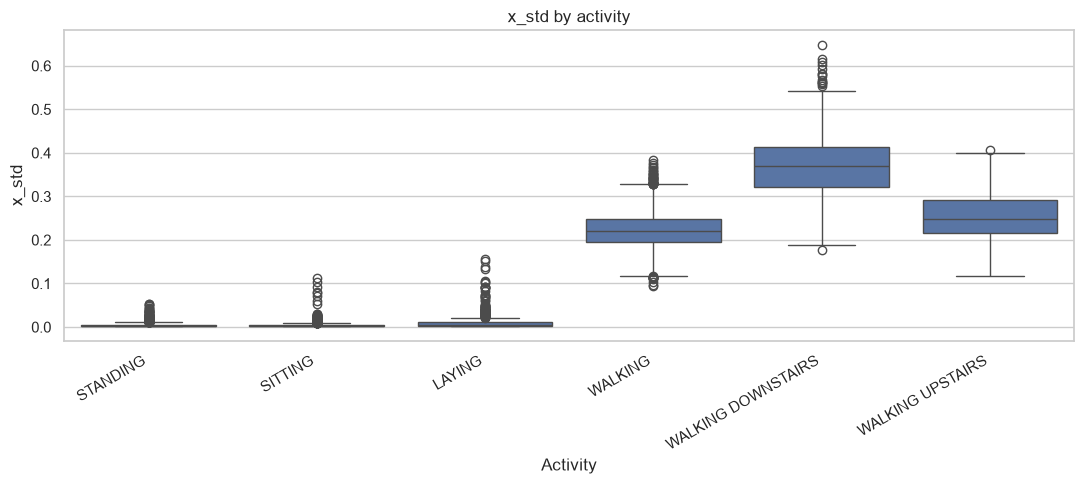

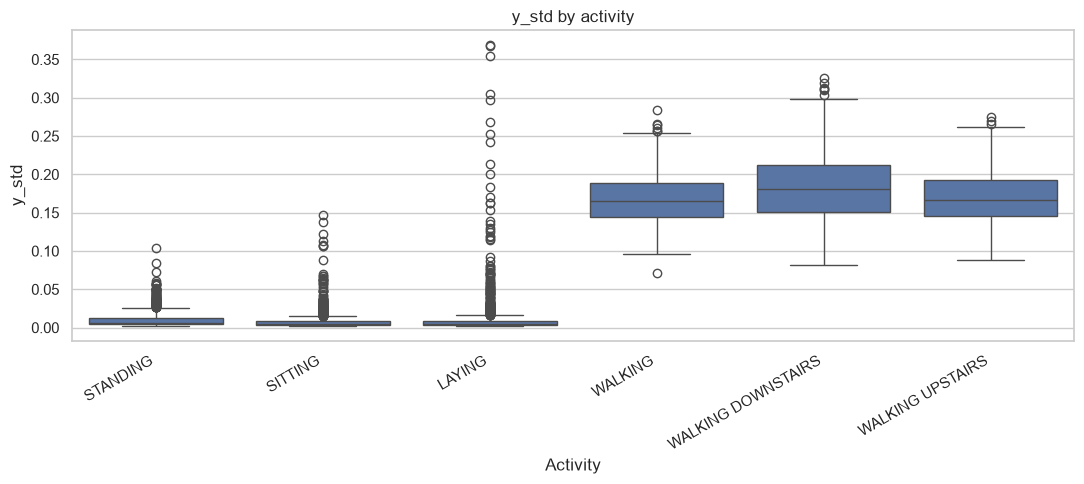

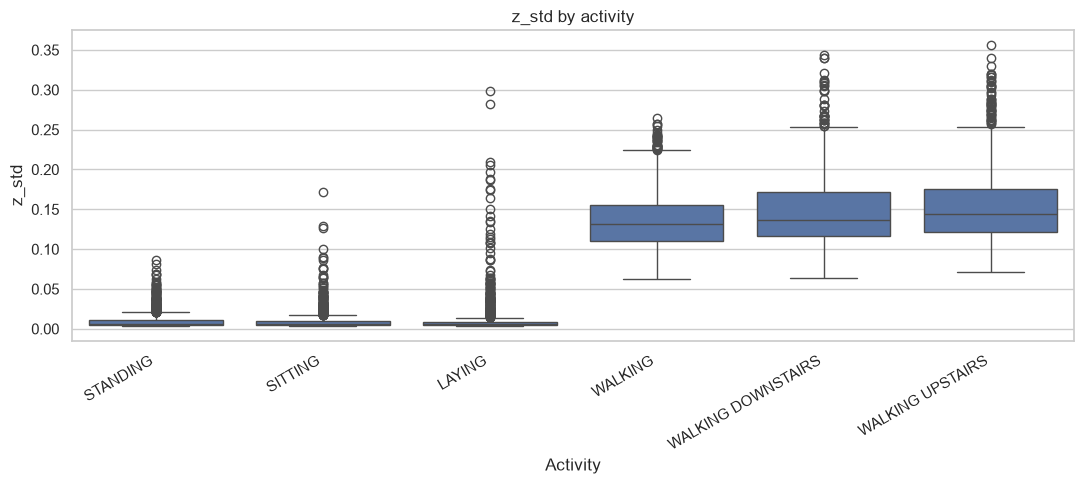

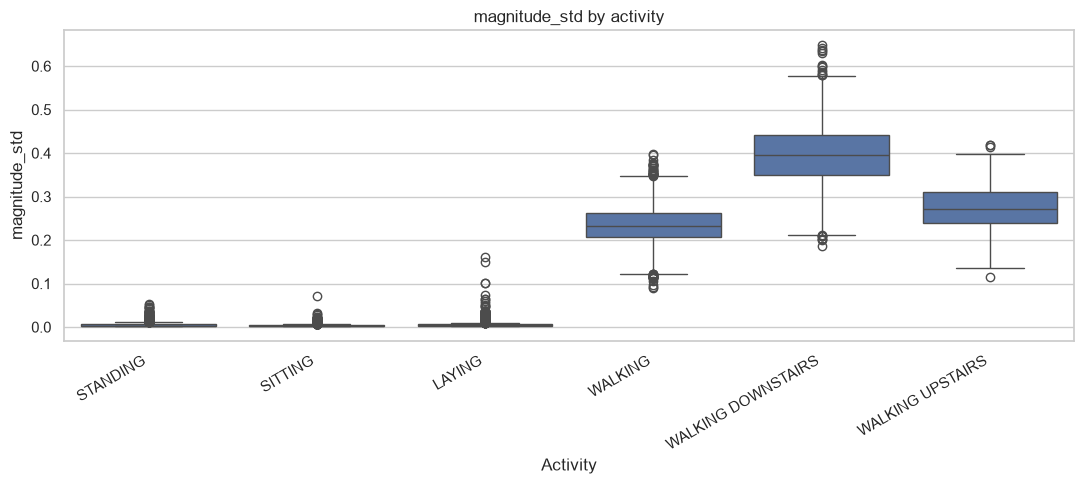

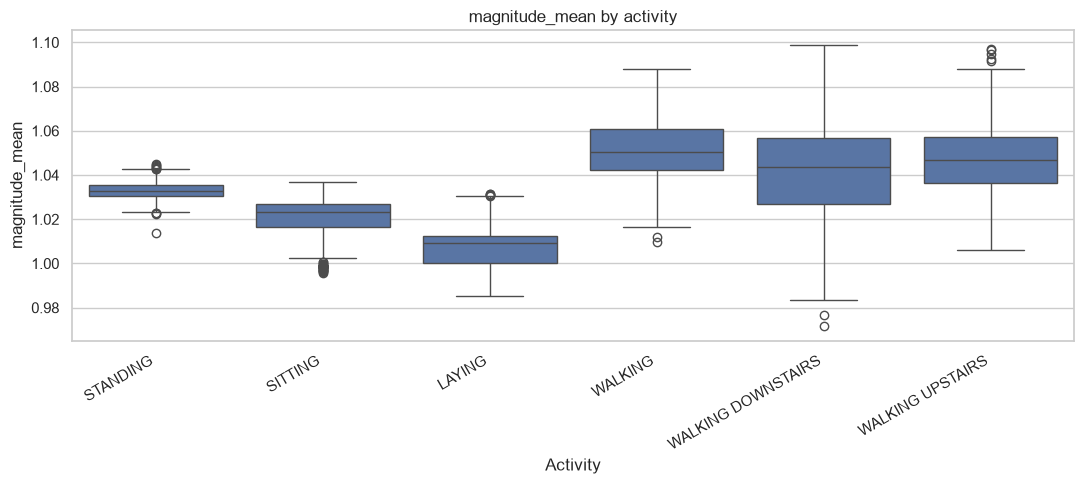

In [20]:

activity_names = {
    i: name.replace("_", " ") for i, name in enumerate(ACTIVITIES)
}

feature_data = X_train_features.copy()
feature_data["activity"] = [
    activity_names[int(label)] for label in y_train
]

features_to_plot = [
    "x_std",
    "y_std",
    "z_std",
    "magnitude_std",
    "magnitude_mean",
]

for feature in features_to_plot:
    plt.figure(figsize=(11, 5))
    sns.boxplot(
        data=feature_data,
        x="activity",
        y=feature,
    )
    plt.title(f"{feature} by activity")
    plt.xlabel("Activity")
    plt.ylabel(feature)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


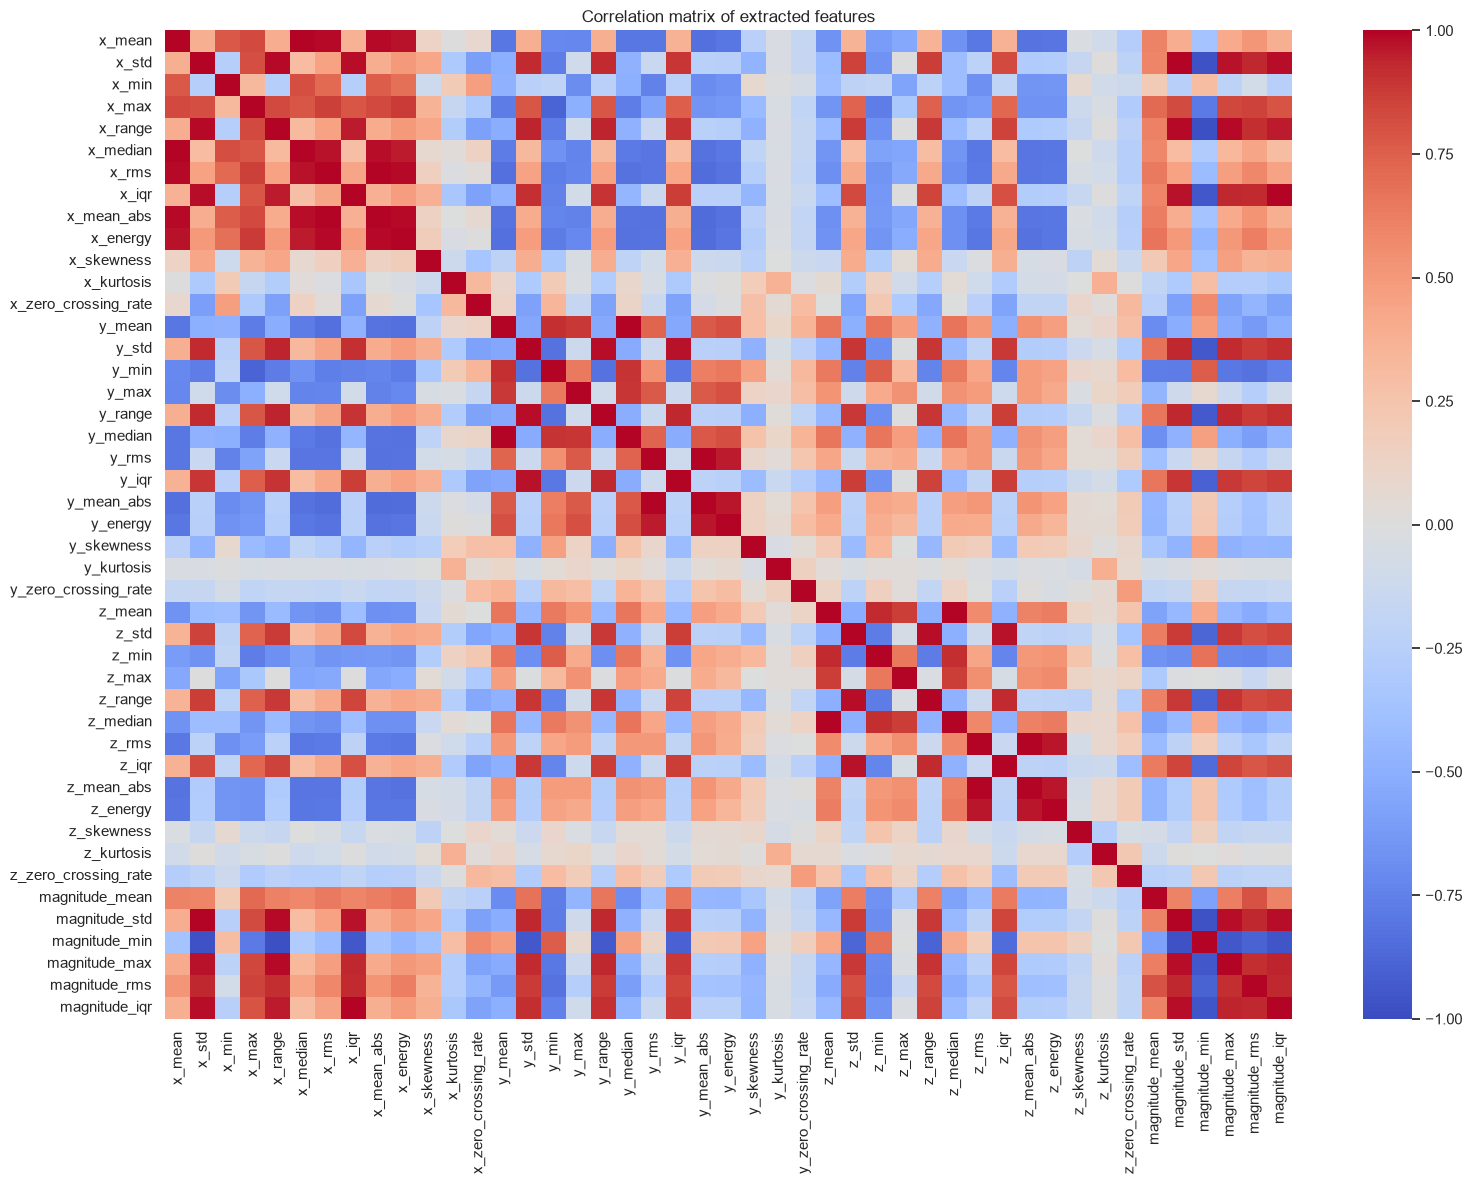

In [21]:

corr = X_train_features.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation matrix of extracted features")
plt.tight_layout()
plt.show()



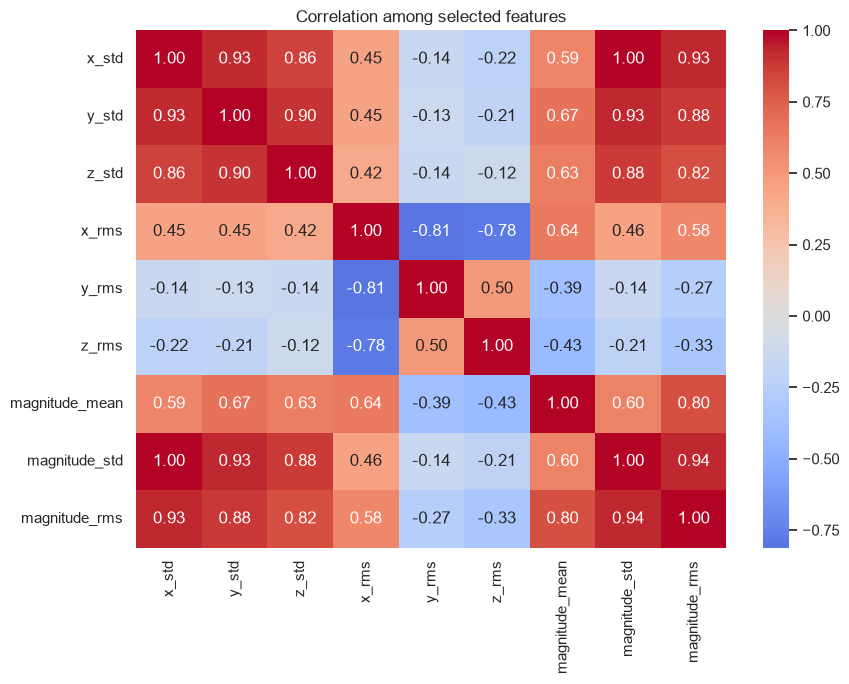

In [22]:
selected = [
    "x_std", "y_std", "z_std",
    "x_rms", "y_rms", "z_rms",
    "magnitude_mean", "magnitude_std",
    "magnitude_rms",
]

plt.figure(figsize=(9, 7))
sns.heatmap(
    X_train_features[selected].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Correlation among selected features")
plt.tight_layout()
plt.show()

In [23]:
feature_dir = PROJECT_ROOT / "data" / "processed"
feature_dir.mkdir(parents=True, exist_ok=True)

X_train_features.to_csv(
    feature_dir / "train_features.csv", index=False
)
X_test_features.to_csv(
    feature_dir / "test_features.csv", index=False
)

np.save(feature_dir / "y_train.npy", y_train_features)
np.save(feature_dir / "y_test.npy", y_test_features)

print("Feature files saved to:", feature_dir)

Feature files saved to: c:\Users\nandi\OneDrive\Desktop\tinyml-har-esp32\data\processed


,importance
x_max,0.077664
magnitude_max,0.059072
magnitude_std,0.055057
y_median,0.052703
x_mean_abs,0.045514
x_mean,0.044755
x_energy,0.044023
y_mean,0.042458
x_std,0.042066
x_range,0.037984


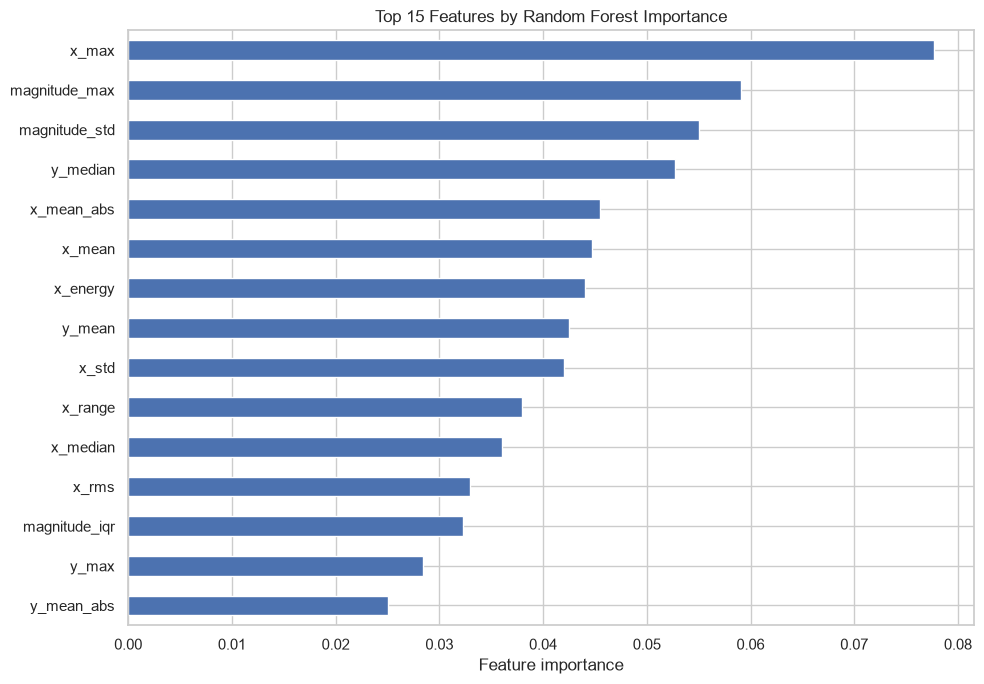

In [24]:

from sklearn.ensemble import RandomForestClassifier

rf_eda = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1,
)

rf_eda.fit(X_train_features, y_train)

importance = pd.Series(
    rf_eda.feature_importances_,
    index=X_train_features.columns,
).sort_values(ascending=False)

display(importance.head(15).to_frame("importance"))

importance.head(15).sort_values().plot(
    kind="barh", figsize=(10, 7)
)
plt.title("Top 15 Features by Random Forest Importance")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()


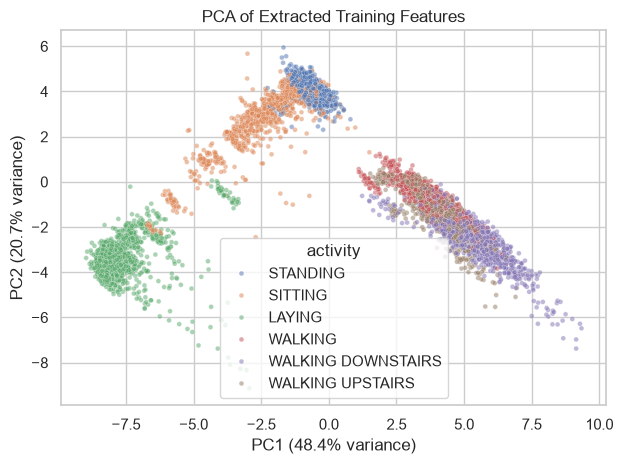

Total variance explained by first 2 PCs: 69.09%


In [25]:

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns

# PCA is fitted on training features only.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_features)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "activity": [ACTIVITIES[i].replace("_", " ") for i in y_train],
})

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="activity",
    s=12,
    alpha=0.5,
)
plt.title("PCA of Extracted Training Features")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.tight_layout()
plt.show()

print("Total variance explained by first 2 PCs:",
      f"{pca.explained_variance_ratio_.sum():.2%}")


In [26]:

corr = X_train_features.corr().abs()

upper = corr.where(
    pd.DataFrame(
        np.triu(np.ones(corr.shape), k=1).astype(bool),
        index=corr.index,
        columns=corr.columns,
    )
)

high_corr = (
    upper.stack()
    .loc[lambda s: s >= 0.95]
    .sort_values(ascending=False)
)

print("Feature pairs with absolute correlation >= 0.95:")
display(high_corr.to_frame("absolute_correlation"))


Feature pairs with absolute correlation >= 0.95:


,,absolute_correlation
y_mean,y_median,0.998913
z_mean,z_median,0.998468
x_rms,x_mean_abs,0.997419
x_std,magnitude_std,0.996996
z_rms,z_mean_abs,0.996197
x_iqr,magnitude_iqr,0.993728
y_rms,y_mean_abs,0.993645
x_mean,x_median,0.993103
x_rms,x_energy,0.991146
x_std,x_range,0.989090


Accuracy: 0.7991 (79.91%)
Macro-F1: 0.7983
Training time: 1.384 seconds
Total test inference time: 0.0722 seconds
Average inference time: 0.025 ms/window

Classification report:
                    precision    recall  f1-score   support

           WALKING     0.6492    0.7238    0.6845       496
  WALKING_UPSTAIRS     0.6882    0.6794    0.6838       471
WALKING_DOWNSTAIRS     0.9133    0.8024    0.8542       420
           SITTING     0.7689    0.7862    0.7774       491
          STANDING     0.7985    0.7820    0.7901       532
            LAYING     1.0000    1.0000    1.0000       537

          accuracy                         0.7991      2947
         macro avg     0.8030    0.7956    0.7983      2947
      weighted avg     0.8039    0.7991    0.8006      2947



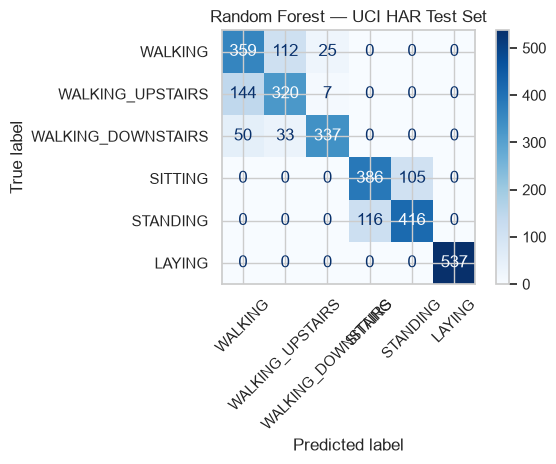

In [27]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt
import pandas as pd
import time

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1,
)

# Measure training time
start = time.perf_counter()
rf.fit(X_train_features, y_train)
train_time = time.perf_counter() - start

# Measure test inference time
start = time.perf_counter()
y_pred = rf.predict(X_test_features)
inference_time = time.perf_counter() - start

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Macro-F1: {macro_f1:.4f}")
print(f"Training time: {train_time:.3f} seconds")
print(f"Total test inference time: {inference_time:.4f} seconds")
print(f"Average inference time: {inference_time / len(y_test) * 1000:.3f} ms/window")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(range(6)),
    target_names=ACTIVITIES,
    digits=4,
    zero_division=0,
))

cm = confusion_matrix(y_test, y_pred, labels=list(range(6)))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=ACTIVITIES,
)
disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Random Forest — UCI HAR Test Set")
plt.tight_layout()
plt.show()


In [28]:

from pathlib import Path
import pandas as pd

results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

baseline = pd.DataFrame([{
    "model": "Random Forest",
    "input": "Statistical features",
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "training_time_s": train_time,
    "test_inference_time_s": inference_time,
    "inference_ms_per_window": inference_time / len(y_test) * 1000,
    "n_test_windows": len(y_test),
}])

baseline.to_csv(results_dir / "rf_baseline.csv", index=False)
display(baseline)
print("Saved to:", results_dir / "rf_baseline.csv")


,model,input,accuracy,macro_f1,training_time_s,test_inference_time_s,inference_ms_per_window,n_test_windows
0,Random Forest,Statistical features,0.799118,0.798339,1.38442,0.072246,0.024515,2947


Saved to: c:\Users\nandi\OneDrive\Desktop\tinyml-har-esp32\results\rf_baseline.csv
